# EDA корпусов SequenceCraft, MFE, EDS и случайной ДНК

Четыре корпуса, на которых держится текущая итерация:

- **SequenceCraft** — экспериментальные каталитические ядра, fine-tune генератора и референс фильтров;
- **MFE** — синтетический корпус для pre-train, отобранный по термодинамике;
- **EDS** — второй синтетический корпус для pre-train;
- **Негативы** — случайная ДНК, контроль пайплайна.

В дизайн-документе синтетические корпуса и контроль названы «около 250 тысяч». Ниже записан фактический объём файлов.

Параметры одни и те же для всех четырёх: число строк и уникальных последовательностей, алфавит, длина, GC, частоты нуклеотидов и динуклеотидов, энтропия Шеннона. Расхождение с SequenceCraft считается по GC, энтропии, нормализованному расстоянию Левенштейна и расстоянию Жаккара по 3-мерам из `statistics/new_stats.py`. Числовой MFE и вторичная структура в этих CSV не лежат, поэтому в общее сравнение они не входят. `kobs` есть только у SequenceCraft и используется как проверка качества разметки, а не как ось сравнения.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

plt.rcParams.update({
    "figure.dpi": 140,
    "axes.grid": False,
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
})

# Палитра и кегль как в visualization/wgan_embedding_umap_hyena.ipynb.
# Для негативов добавлен четвёртый приглушённый цвет: в том ноутбуке серии три.
COLOR_SEQCRAFT = "#D1855C"
COLOR_SAGE = "#98B1A8"
COLOR_GOLD = "#E5BA41"
COLOR_SLATE = "#7C8C9A"
COLORS = {
    "SequenceCraft": COLOR_SEQCRAFT,
    "MFE": COLOR_SAGE,
    "EDS": COLOR_GOLD,
    "Negatives": COLOR_SLATE,
}
ORDER = list(COLORS)
DRAW_ORDER = ["MFE", "EDS", "Negatives", "SequenceCraft"]
AX_LABEL_FONTSIZE = 14
AX_TICK_FONTSIZE = 12
LEGEND_FONTSIZE = 11


def style_axes(ax, xlabel: str, ylabel: str) -> None:
    ax.set_xlabel(xlabel, fontsize=AX_LABEL_FONTSIZE)
    ax.set_ylabel(ylabel, fontsize=AX_LABEL_FONTSIZE)
    ax.tick_params(axis="both", labelsize=AX_TICK_FONTSIZE)


LINESTYLES = {
    "SequenceCraft": "-",
    "MFE": "-",
    "EDS": (0, (4, 1.5)),
    "Negatives": (0, (1, 1.2)),
}


def density_curve(values: np.ndarray, bins: np.ndarray, bandwidth: float):
    grid = np.linspace(float(bins[0]), float(bins[-1]), 700)
    std = float(np.std(values))
    factor = bandwidth / std if std > 0 else 1.0
    kde = gaussian_kde(values, bw_method=factor)
    return grid, kde(grid)


def plot_density(ax, values: np.ndarray, bins: np.ndarray, name: str, bandwidth: float) -> None:
    centers, curve = density_curve(values, bins, bandwidth=bandwidth)
    ax.plot(
        centers,
        curve,
        color=COLORS[name],
        linestyle=LINESTYLES[name],
        linewidth=2.2,
        label=name,
        solid_capstyle="round",
        zorder=3 if name == "EDS" else 2,
    )


def add_legend(ax) -> None:
    handles, labels = ax.get_legend_handles_labels()
    positions = {label: handle for handle, label in zip(handles, labels)}
    ordered = [name for name in ORDER if name in positions]
    ax.legend(
        [positions[name] for name in ordered],
        ordered,
        loc="best",
        framealpha=0.92,
        fontsize=LEGEND_FONTSIZE,
    )


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        marker = candidate / "Data" / "Sequence_Craft" / "SequenceCraft_dataset.csv"
        if marker.exists():
            return candidate
    raise FileNotFoundError("Не найден корень репозитория с Data/Sequence_Craft")


ROOT = find_root()
DATA = ROOT / "Data"
SOURCES = {
    "SequenceCraft": (DATA / "Sequence_Craft" / "SequenceCraft_dataset.csv", "e"),
    "MFE": (DATA / "MFE" / "seq2 - seq2.csv", "Sequence"),
    "EDS": (DATA / "EDS" / "distrib_result.csv", "sequence"),
    "Negatives": (DATA / "Negatives" / "dna_sequences.csv", "sequence"),
}
ALPHABET = "ACGT"
DINUCS = [a + b for a in ALPHABET for b in ALPHABET]
LUT = np.full(128, -1, np.int8)
for index, base in enumerate(b"ACGT"):
    LUT[base] = index


def load_sequences(path: Path, column: str) -> np.ndarray:
    series = pd.read_csv(path, usecols=[column])[column].astype(str)
    return series.to_numpy()


corpora = {name: load_sequences(path, column) for name, (path, column) in SOURCES.items()}
for name in ORDER:
    print(f"{name:14} {len(corpora[name]):7d}  {SOURCES[name][0].relative_to(ROOT)}")


SequenceCraft      549  Data/Sequence_Craft/SequenceCraft_dataset.csv
MFE             232885  Data/MFE/seq2 - seq2.csv
EDS             277765  Data/EDS/distrib_result.csv
Negatives       250000  Data/Negatives/dna_sequences.csv


## Объём и качество

Сначала проверяется, можно ли вообще сравнивать корпуса как наборы последовательностей ДНК: нет ли пустых строк, букв вне `ACGT` и копий одной и той же последовательности. Для SequenceCraft отдельно смотрится, сходятся ли значения `kobs` на повторяющихся ядрах.


In [4]:
def quality_table(corpora: dict[str, np.ndarray]) -> pd.DataFrame:
    reference = set(corpora["SequenceCraft"])
    rows = []
    for name in ORDER:
        sequences = pd.Series(corpora[name])
        rows.append({
            "корпус": name,
            "строк": int(len(sequences)),
            "уникальных": int(sequences.nunique()),
            "повторов строк": int(len(sequences) - sequences.nunique()),
            "пустых": int((sequences.str.len() == 0).sum()),
            "не ACGT": int((~sequences.str.fullmatch(r"[ACGT]+")).sum()),
            "общих с SequenceCraft": int(len(set(sequences) & reference)),
        })
    return pd.DataFrame(rows)


quality = quality_table(corpora)
print(quality.to_string(index=False))

sc = pd.read_csv(SOURCES["SequenceCraft"][0], usecols=["e", "kobs"])
multiplicity = sc.groupby("e").size()
kobs_variants = sc.groupby("e").kobs.nunique()
repeated = multiplicity[multiplicity > 1].index
print()
print(f"Повторяющихся ядер SequenceCraft: {len(repeated)}")
print(f"Максимальное число копий одной последовательности: {int(multiplicity.max())}")
print(f"Из них с разными kobs: {int((kobs_variants.loc[repeated] > 1).sum())}")
print(f"kobs заполнен у всех строк: {int(sc.kobs.notna().sum())} из {len(sc)}")


       корпус  строк  уникальных  повторов строк  пустых  не ACGT  общих с SequenceCraft
SequenceCraft    549         349             200       0        0                    349
          MFE 232885      232885               0       0        0                      0
          EDS 277765      277765               0       0        0                      0
    Negatives 250000      250000               0       0        0                      0

Повторяющихся ядер SequenceCraft: 14
Максимальное число копий одной последовательности: 41
Из них с разными kobs: 13
kobs заполнен у всех строк: 549 из 549


**Вывод.** Пустых строк и букв вне `ACGT` нет ни в одном корпусе, пересечения последовательностей с SequenceCraft тоже нет: MFE, EDS и случайная ДНК не копируют экспериментальные ядра.

Фактический объём не равен круглой оценке «250 тысяч». MFE содержит 232 885 уникальных последовательностей, EDS — 277 765, негативы — ровно 250 000. SequenceCraft — это 549 строк и только 349 уникальных ядер. 14 ядер повторяются, одно из них до 41 раза, и у 13 повторов в разных строках записан разный `kobs`. Для fine-tune и для позитивов классификатора повтор меняет вес ядра, а порог активности нельзя однозначно восстановить по последовательности.


## Длина

Длина — первый параметр, который должен совпадать, если pre-train претендует на то же пространство ядер, что и SequenceCraft. Негативы по построению берут длину из Beta(7.0, 7.5), растянутой на отрезок [8, 74].

Ниже SequenceCraft участвует уже без повторных строк: 349 уникальных ядер. Иначе одна и та же последовательность учитывается много раз и гистограмма длины перестаёт описывать набор ядер.


В распределениях SequenceCraft: 349 уникальных ядер
       корпус  min  q25  медиана  среднее  q75  max
SequenceCraft    8 37.0     40.0     40.2 49.0   74
          MFE   21 65.0     71.0     68.8 75.0   78
          EDS   14 37.0     40.0     40.2 49.0   74
    Negatives   12 34.0     40.0     39.9 46.0   71


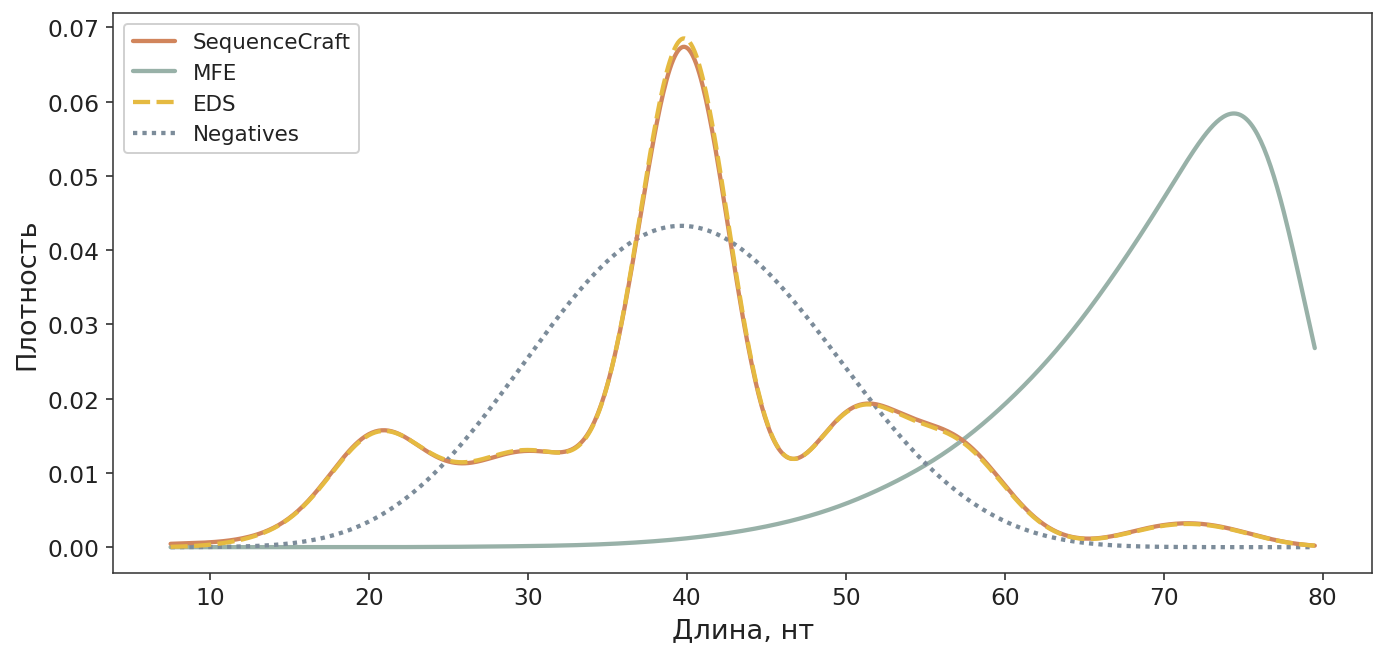

In [7]:
def sequence_features(sequences: np.ndarray) -> dict[str, np.ndarray]:
    count = len(sequences)
    mono = np.zeros((count, 4), dtype=np.int32)
    dinucleotide = np.zeros((count, 16), dtype=np.int32)
    trinucleotide = np.zeros(64, dtype=np.int64)
    length = np.empty(count, dtype=np.int32)
    entropy = np.empty(count, dtype=np.float64)
    for index, sequence in enumerate(sequences):
        encoded = np.frombuffer(sequence.encode("ascii"), dtype=np.uint8)
        bases = LUT[encoded]
        if np.any(bases < 0):
            raise ValueError("В последовательности есть символ вне ACGT")
        length[index] = encoded.size
        base_counts = np.bincount(bases, minlength=4)
        mono[index] = base_counts
        if encoded.size > 1:
            pairs = bases[:-1] * 4 + bases[1:]
            dinucleotide[index] = np.bincount(pairs, minlength=16)
        if encoded.size > 2:
            triples = bases[:-2] * 16 + bases[1:-1] * 4 + bases[2:]
            trinucleotide += np.bincount(triples, minlength=64)
        probability = base_counts / encoded.size
        probability = probability[probability > 0]
        entropy[index] = -np.sum(probability * np.log2(probability))
    gc = (mono[:, 1] + mono[:, 2]) / length
    return {
        "length": length,
        "gc": gc,
        "entropy": entropy,
        "mono": mono,
        "dinucleotide": dinucleotide,
        "trinucleotide": trinucleotide,
    }


# Повторные строки SequenceCraft — это повторные записи одного ядра, не новые последовательности.
# Дальше SequenceCraft берётся по уникальным ядрам, иначе длина и состав смещаются весом копий.
distribution_corpora = {
    name: pd.unique(sequences) if name == "SequenceCraft" else sequences
    for name, sequences in corpora.items()
}
print("В распределениях SequenceCraft:", len(distribution_corpora["SequenceCraft"]), "уникальных ядер")
features = {name: sequence_features(distribution_corpora[name]) for name in ORDER}

length_rows = []
for name in ORDER:
    values = features[name]["length"]
    length_rows.append({
        "корпус": name,
        "min": int(values.min()),
        "q25": float(np.quantile(values, 0.25)),
        "медиана": float(np.median(values)),
        "среднее": float(values.mean()),
        "q75": float(np.quantile(values, 0.75)),
        "max": int(values.max()),
    })
length_table = pd.DataFrame(length_rows)
print(length_table.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.arange(7.5, 80.5, 1)
for name in ["MFE", "Negatives", "SequenceCraft", "EDS"]:
    plot_density(ax, features[name]["length"], bins, name, bandwidth=2.8)
style_axes(ax, "Длина, нт", "Плотность")
add_legend(ax)
fig.tight_layout()
plt.show()


**Вывод.** После удаления повторов длина SequenceCraft и EDS совпадает: медиана 40, квартили 37 и 49, среднее 40.2. EDS воспроизводит эмпирическую длину экспериментальных ядер

Негативы имеют ту же медиану 40, но распределение уже в центре (квартили 34 и 46). Длина там взята из гладкого Beta(7.0, 7.5), а не из гистограммы SequenceCraft, поэтому совпадение медианы не означает совпадение формы.

MFE — другой объект. Медиана 71, квартили 65 и 75. Pre-train на MFE учит преимущественно длинные цепи, а fine-tune переносит модель на ядра около 40 нуклеотидов.


## Состав: нуклеотиды и GC

GC и доли A/C/G/T считаются по всем символам корпуса, одним и тем же способом. Доля GC на графике — распределение по последовательностям, столбцы — суммарный состав корпуса.


       корпус  GC среднее  GC std     A     C     G     T
SequenceCraft       0.542   0.085 0.232 0.214 0.320 0.233
          MFE       0.555   0.059 0.227 0.271 0.282 0.220
          EDS       0.500   0.083 0.250 0.250 0.250 0.250
    Negatives       0.500   0.081 0.250 0.250 0.250 0.250


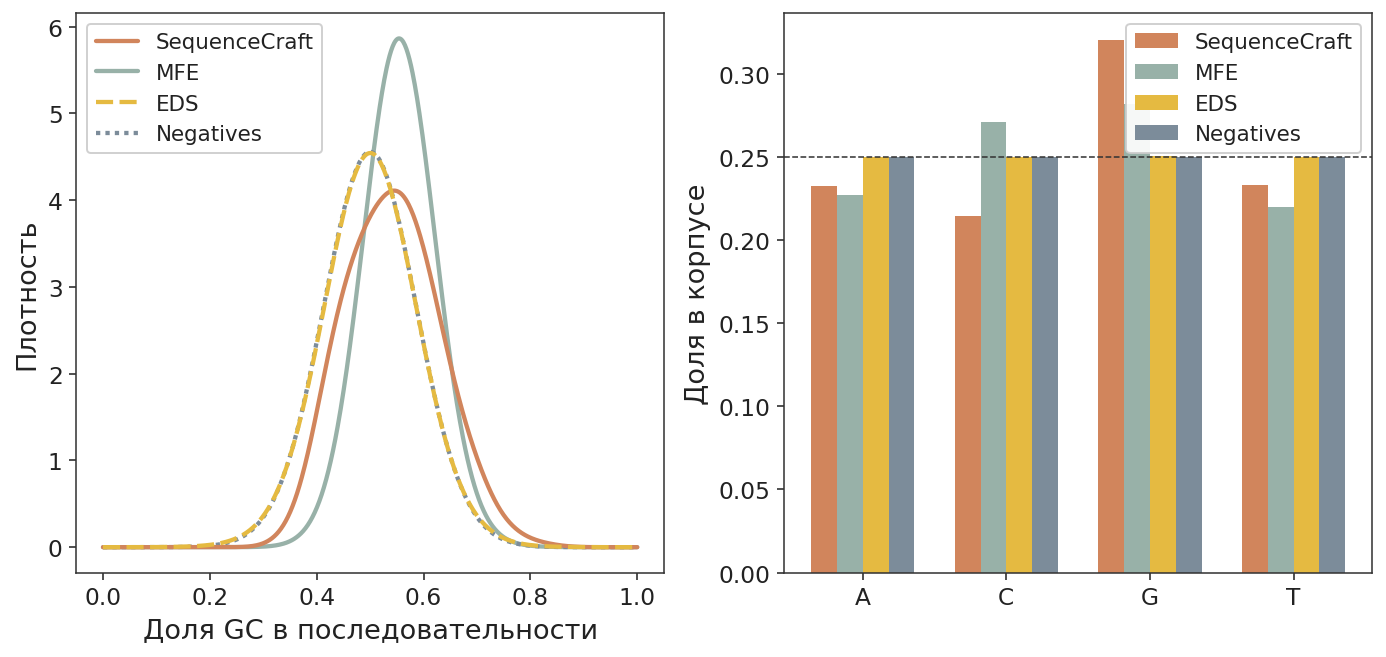

In [10]:
composition_rows = []
for name in ORDER:
    gc = features[name]["gc"]
    mono = features[name]["mono"].sum(axis=0)
    mono = mono / mono.sum()
    composition_rows.append({
        "корпус": name,
        "GC среднее": float(gc.mean()),
        "GC std": float(gc.std()),
        "A": float(mono[0]),
        "C": float(mono[1]),
        "G": float(mono[2]),
        "T": float(mono[3]),
    })
composition = pd.DataFrame(composition_rows)
print(composition.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
bins = np.linspace(0, 1, 41)
for name in ["MFE", "Negatives", "SequenceCraft", "EDS"]:
    plot_density(axes[0], features[name]["gc"], bins, name, bandwidth=0.035)
style_axes(axes[0], "Доля GC в последовательности", "Плотность")
add_legend(axes[0])

x = np.arange(4)
width = 0.18
for offset, name in enumerate(ORDER):
    mono = features[name]["mono"].sum(axis=0)
    mono = mono / mono.sum()
    axes[1].bar(
        x + (offset - 1.5) * width,
        mono,
        width=width,
        color=COLORS[name],
        linewidth=0,
        label=name,
    )
axes[1].axhline(0.25, color="#333333", linewidth=0.8, linestyle="--")
axes[1].set_xticks(x, list(ALPHABET))
style_axes(axes[1], "", "Доля в корпусе")
add_legend(axes[1])
fig.tight_layout()
plt.show()


**Вывод.** Уникальные ядра SequenceCraft не равномерны: G составляет 32.0%, C — 21.4%, средний GC — 0.54. Повторные строки этот сдвиг немного разбавляли. EDS и негативы по составу совпадают друг с другом и с равномерным алфавитом: каждая буква около 0.25, средний GC равен 0.50. MFE сдвинут в GC сильнее всех по среднему, 0.55, за счёт C (27.1%) и G (28.2%).

EDS поэтому повторяет SequenceCraft по длине и не повторяет его по буквам. Локально он устроен как случайная ДНК. MFE ближе к экспериментальным ядрам по избытку G, но приносит избыток C, которого в SequenceCraft нет.


## Динуклеотиды

Динуклеотид считается по соседним буквам внутри каждой последовательности и нормируется на число пар в корпусе. На тепловой карте виден сырой состав. Рядом — отличие от SequenceCraft в процентных пунктах: положительное значение значит, что пара встречается чаще, чем в экспериментальных ядрах.


Самые частые пары SequenceCraft:
GG 0.098, GT 0.081, AG 0.079, TG 0.077, GA 0.070
MFE: CC +2.70, GG -2.06, GT -2.01, AG -1.77
EDS: GG -3.58, CC +1.89, GT -1.83, TC +1.80
Negatives: GG -3.59, CC +1.89, GT -1.83, TC +1.80


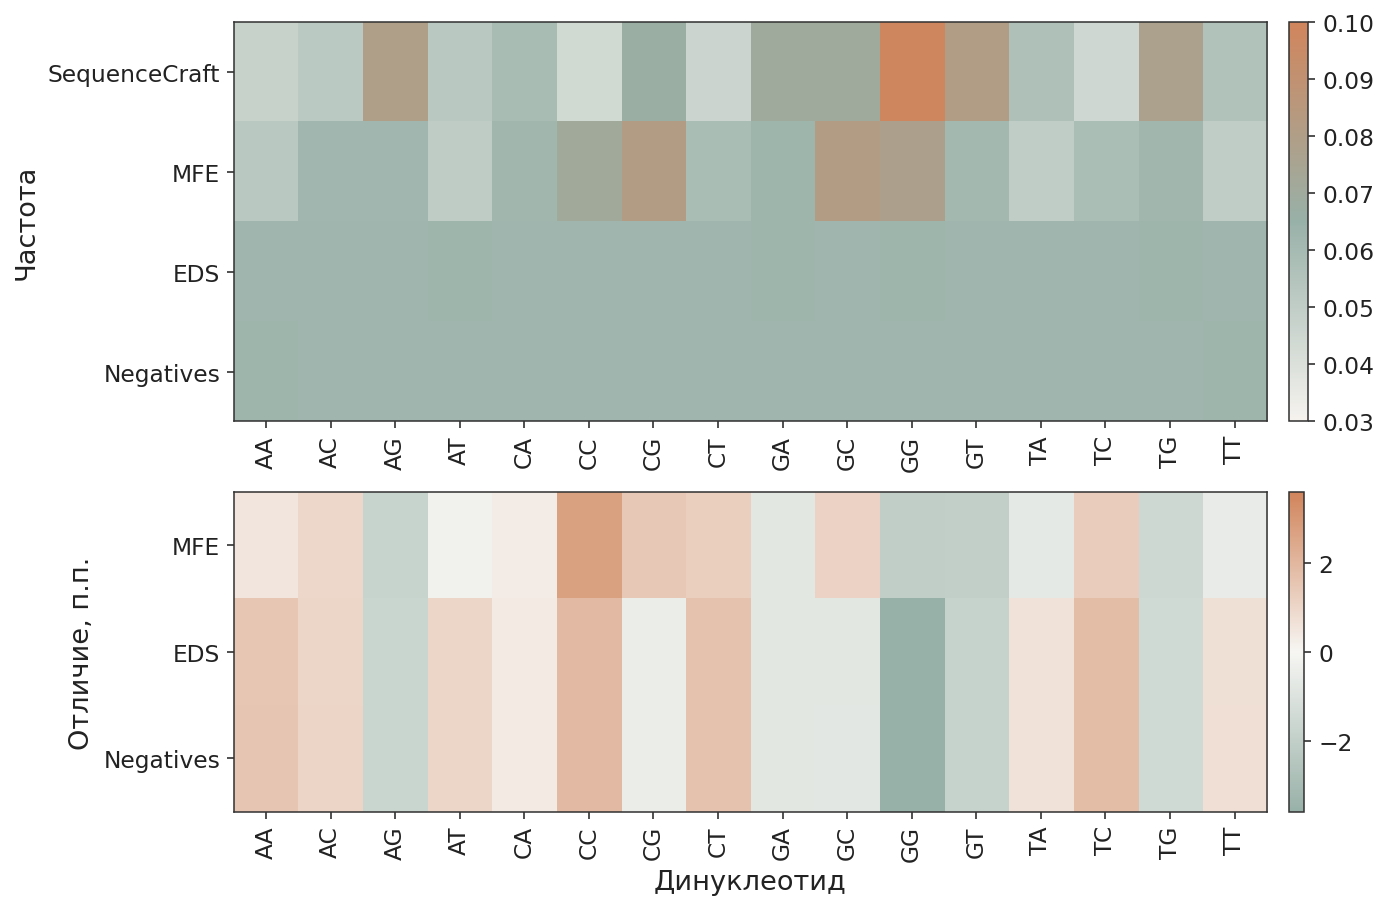

In [13]:
def dinucleotide_frequency(name: str) -> np.ndarray:
    counts = features[name]["dinucleotide"].sum(axis=0).astype(float)
    return counts / counts.sum()


frequency = np.vstack([dinucleotide_frequency(name) for name in ORDER])
reference = frequency[0]
delta = (frequency[1:] - reference) * 100

from matplotlib.colors import LinearSegmentedColormap

frequency_cmap = LinearSegmentedColormap.from_list(
    "eda_frequency", ["#F6F3EF", COLOR_SAGE, COLOR_SEQCRAFT]
)
delta_cmap = LinearSegmentedColormap.from_list(
    "eda_delta", [COLOR_SAGE, "#F7F6F3", COLOR_SEQCRAFT]
)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), gridspec_kw={"height_ratios": [1, 0.8]})
image = axes[0].imshow(frequency, aspect="auto", cmap=frequency_cmap, vmin=0.03, vmax=0.10)
axes[0].set_yticks(range(len(ORDER)), ORDER)
axes[0].set_xticks(range(16), DINUCS, rotation=90)
axes[0].tick_params(axis="both", labelsize=AX_TICK_FONTSIZE)
frequency_bar = fig.colorbar(image, ax=axes[0], fraction=0.025, pad=0.02)
frequency_bar.ax.tick_params(labelsize=AX_TICK_FONTSIZE)
style_axes(axes[0], "", "Частота")

delta_image = axes[1].imshow(delta, aspect="auto", cmap=delta_cmap, vmin=-3.6, vmax=3.6)
axes[1].set_yticks(range(3), ORDER[1:])
axes[1].set_xticks(range(16), DINUCS, rotation=90)
axes[1].tick_params(axis="both", labelsize=AX_TICK_FONTSIZE)
delta_bar = fig.colorbar(delta_image, ax=axes[1], fraction=0.025, pad=0.02)
delta_bar.ax.tick_params(labelsize=AX_TICK_FONTSIZE)
style_axes(axes[1], "Динуклеотид", "Отличие, п.п.")
fig.tight_layout()
plt.show()

sc_order = np.argsort(-reference)[:5]
print("Самые частые пары SequenceCraft:")
print(", ".join(f"{DINUCS[i]} {reference[i]:.3f}" for i in sc_order))
for row, name in enumerate(ORDER[1:], start=0):
    top = np.argsort(-np.abs(delta[row]))[:4]
    pieces = [f"{DINUCS[i]} {delta[row, i]:+.2f}" for i in top]
    print(f"{name}: " + ", ".join(pieces))


**Вывод.** В уникальных ядрах SequenceCraft самые частые пары содержат G: GG, GT, AG, TG. Это продолжение нуклеотидного сдвига, а не отдельный мотив.

EDS и негативы отходят от SequenceCraft одинаково: GG реже примерно на 3.6 п.п., CC чаще примерно на 1.9 п.п. По динуклеотидам EDS не отличается от случайной ДНК. MFE тоже теряет GG и GT, но добавляет CC: это след отбора на более GC-богатые цепи из-за логики расчета MFE


## Энтропия Шеннона

Энтропия считается внутри каждой последовательности по частотам четырёх букв, в битах. Максимум для алфавита из четырёх букв — 2. Низкая энтропия означала бы гомополимерные или сильно смещённые ядра.


       корпус  среднее  медиана   std   q05
SequenceCraft    1.914    1.940 0.095 1.760
          MFE    1.965    1.973 0.031 1.906
          EDS    1.939    1.954 0.059 1.829
    Negatives    1.941    1.956 0.051 1.842


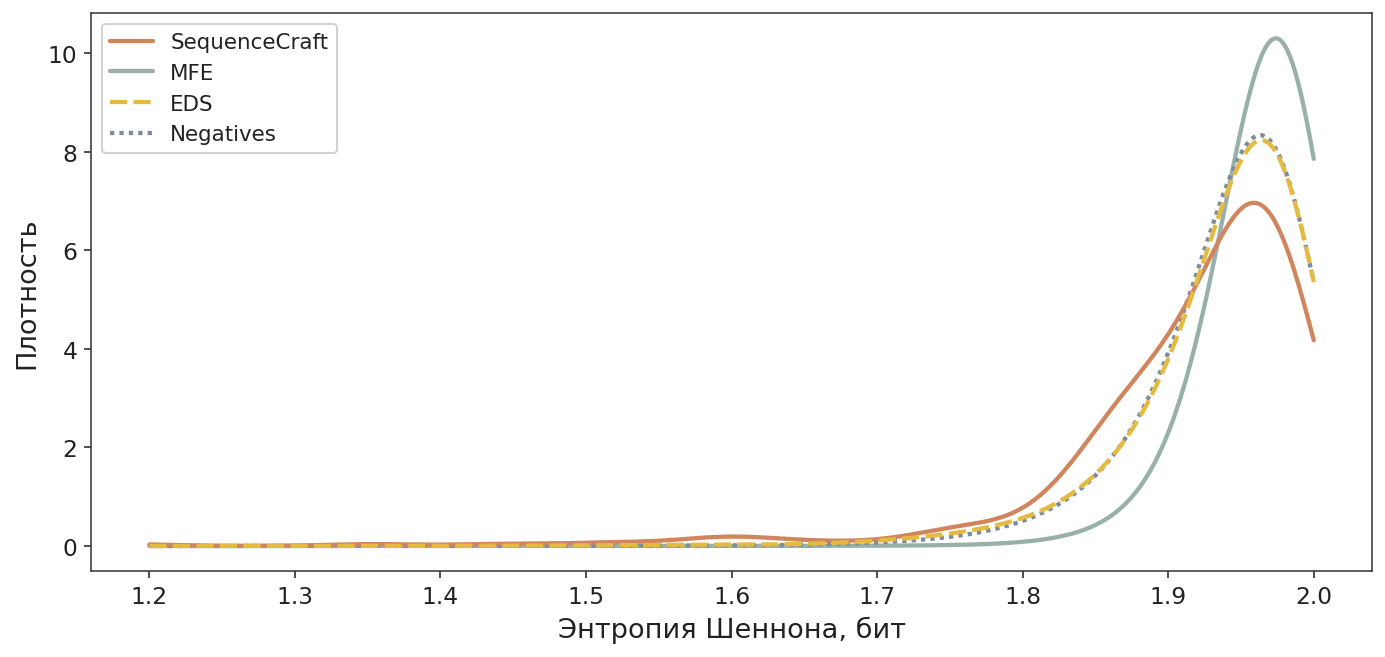

In [16]:
entropy_rows = []
for name in ORDER:
    values = features[name]["entropy"]
    entropy_rows.append({
        "корпус": name,
        "среднее": float(values.mean()),
        "медиана": float(np.median(values)),
        "std": float(values.std()),
        "q05": float(np.quantile(values, 0.05)),
    })
print(pd.DataFrame(entropy_rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.linspace(1.2, 2.0, 40)
for name in ["MFE", "Negatives", "SequenceCraft", "EDS"]:
    plot_density(ax, features[name]["entropy"], bins, name, bandwidth=0.03)
style_axes(ax, "Энтропия Шеннона, бит", "Плотность")
add_legend(ax)
fig.tight_layout()
plt.show()


**Вывод.** Все четыре корпуса лежат у верхней границы алфавита из четырёх букв. Гомополимеров, которые стоило бы вычищать отдельным фильтром, нет. Уникальные ядра SequenceCraft чуть ниже остальных: среднее 1.91 против 1.94 у EDS и негативов и 1.97 у MFE. MFE самый узкий (std 0.031): длинные цепи без сильного перекоса в одну букву. EDS и негативы снова почти совпадают между собой и оба выше SequenceCraft, потому что их состав ближе к равномерному.


## Расхождение с SequenceCraft

Референс — 349 уникальных ядер. Сравнение идёт по GC, энтропии Шеннона, минимальному нормализованному расстоянию Левенштейна и расстоянию Жаккара по 3-мерам.

Левенштейн считается как в скрининге: расстояние редактирования делится на максимум длин двух последовательностей, затем берётся минимум по 349 ядрам. У самого SequenceCraft последовательность не сравнивается сама с собой, иначе все расстояния были бы нулевыми. JSD этого распределения — 20 бинов на [0, 1].

GC и энтропия считаются так же, как `calculate_jsd_gc` и `calculate_jsd_entropy` в `statistics/new_stats.py`: натуральный логарифм, 20 бинов, пустой бин заменяется на 1e-10, гистограмма нормируется. Для GC отрезок [0, 1]. Для энтропии границы бинов — общий минимум и максимум двух корпусов. Длина остаётся отдельной осью: один бин на нуклеотид, от 8 до 80.

APJD и MPD — второе расстояние из того же файла. Это среднее расстояние Жаккара по 3-мерам на 100 000 случайных парах, seed 42. APJD — пары «последовательность корпуса × ядро SequenceCraft». MPD — пары внутри одного корпуса. Ноль JSD означает совпадение гистограммы с уникальными ядрами.


       корпус   min   q25  медиана  среднее   q75   max
SequenceCraft 0.025 0.207    0.350    0.308 0.423 0.571
          MFE 0.318 0.453    0.469    0.467 0.483 0.559
          EDS 0.227 0.425    0.442    0.440 0.456 0.586
    Negatives 0.227 0.422    0.438    0.435 0.450 0.565
       корпус  длина     GC  энтропия  Левенштейн   APJD    MPD
          MFE 0.5293 0.0319    0.0885      0.3586 0.6450 0.5142
          EDS 0.0020 0.0344    0.0173      0.2479 0.7225 0.7179
    Negatives 0.2644 0.0408    0.0194      0.2374 0.7207 0.7138
SequenceCraft 0.0000 0.0000    0.0000      0.0000 0.7040 0.7057


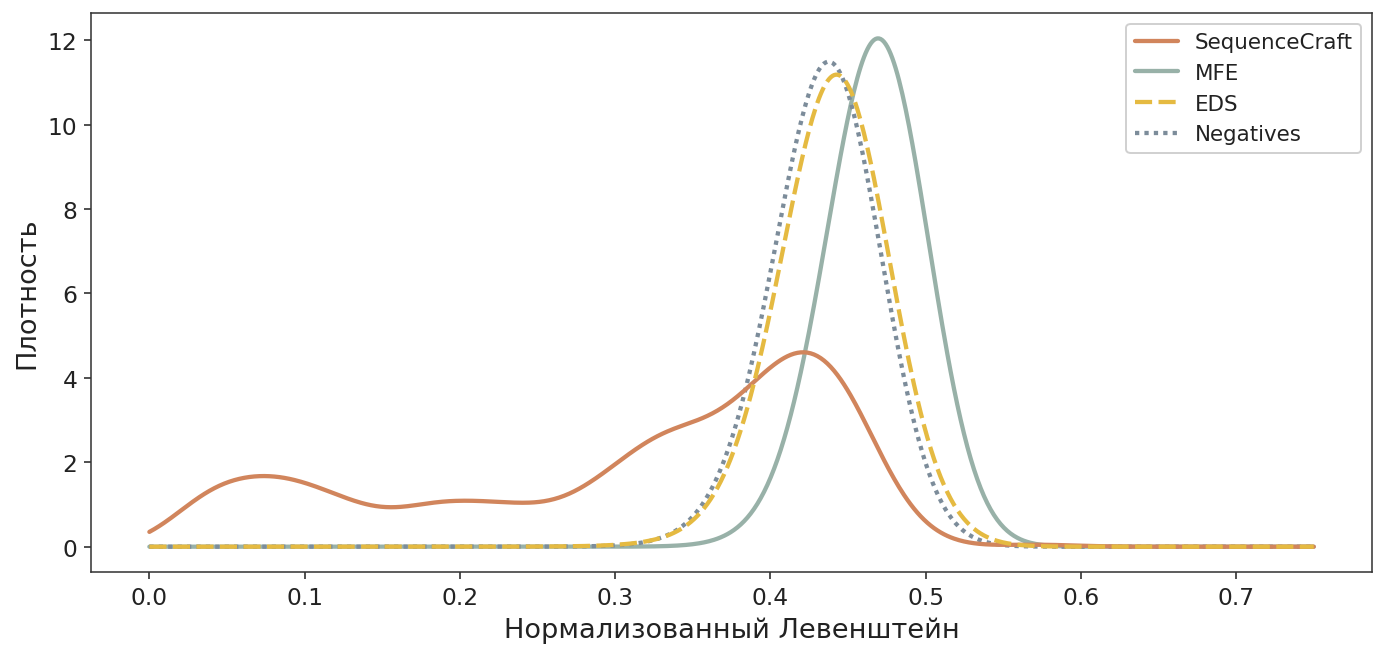

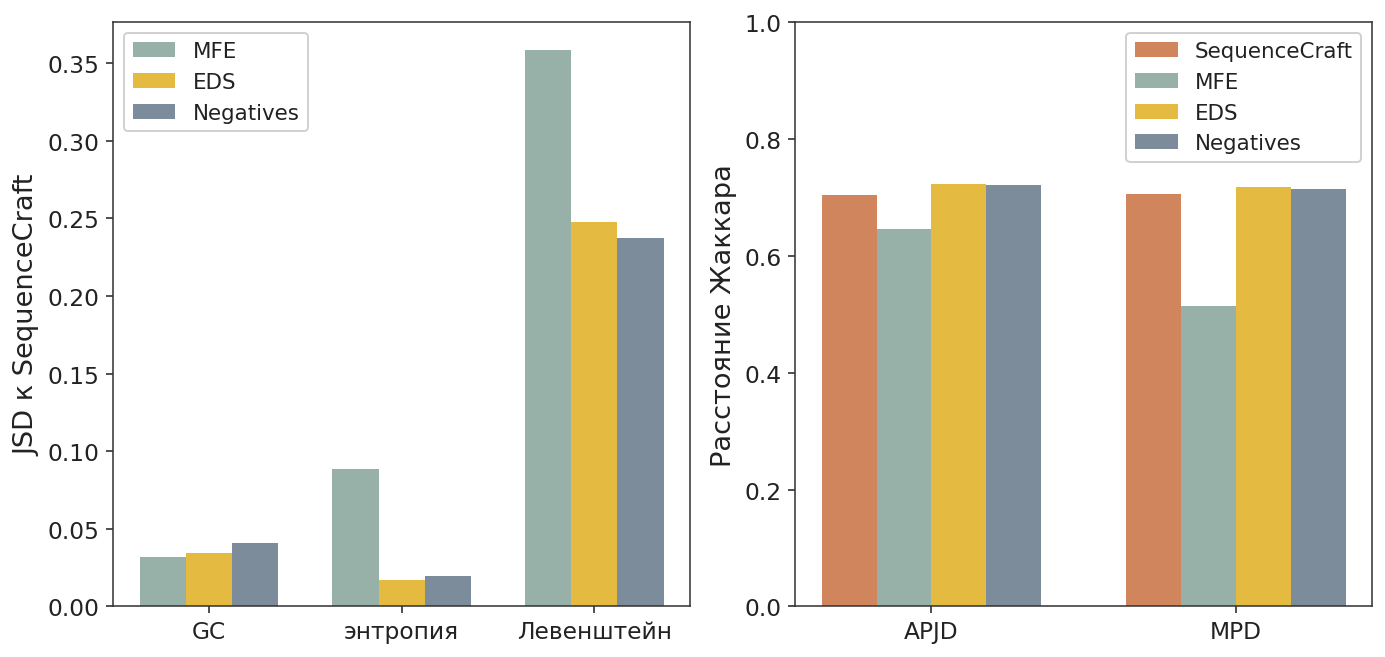

In [19]:
import random

import Levenshtein


def histogram_jsd(left: np.ndarray, right: np.ndarray, bins: int = 20, value_range: tuple[float, float] | None = None) -> float:
    """JSD гистограмм, как calculate_jsd_gc / calculate_jsd_entropy в statistics/new_stats.py."""
    hist_left, edges = np.histogram(left, bins=bins, range=value_range, density=True)
    hist_right, _ = np.histogram(right, bins=edges, density=True)
    hist_left = np.maximum(hist_left, 1e-10)
    hist_right = np.maximum(hist_right, 1e-10)
    hist_left = hist_left / hist_left.sum()
    hist_right = hist_right / hist_right.sum()
    mixture = 0.5 * (hist_left + hist_right)
    kl_left = float(np.sum(hist_left * np.log(hist_left / mixture)))
    kl_right = float(np.sum(hist_right * np.log(hist_right / mixture)))
    return 0.5 * (kl_left + kl_right)


def count_jsd(left: np.ndarray, right: np.ndarray) -> float:
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left = left / left.sum()
    right = right / right.sum()
    mixture = 0.5 * (left + right)
    def kl(source: np.ndarray) -> float:
        mask = source > 0
        return float(np.sum(source[mask] * np.log(source[mask] / mixture[mask])))
    return 0.5 * (kl(left) + kl(right))


def min_normalized_levenshtein(sequences: np.ndarray, reference: np.ndarray, exclude_self: bool) -> np.ndarray:
    reference_lengths = [len(item) for item in reference]
    distances = np.empty(len(sequences), dtype=np.float64)
    for index, sequence in enumerate(sequences):
        length = len(sequence)
        best = 1.0
        for other_index, other in enumerate(reference):
            if exclude_self and other_index == index:
                continue
            distance = Levenshtein.distance(sequence, other) / max(length, reference_lengths[other_index])
            if distance < best:
                best = distance
                if best == 0.0:
                    break
        distances[index] = best
    return distances


def kmer_sets(sequences: np.ndarray, k: int = 3) -> list[frozenset]:
    return [frozenset(sequence[i:i + k] for i in range(len(sequence) - k + 1)) for sequence in sequences]


def jaccard_distance(left: frozenset, right: frozenset) -> float:
    intersection = len(left & right)
    union = len(left) + len(right) - intersection
    return 1.0 - intersection / union if union else 1.0


def sampled_apjd(generated: list[frozenset], reference: list[frozenset], n_samples: int = 100_000, seed: int = 42) -> float:
    rng = random.Random(seed)
    total = 0.0
    for _ in range(n_samples):
        total += jaccard_distance(rng.choice(generated), rng.choice(reference))
    return total / n_samples


def sampled_mpd(sets: list[frozenset], n_samples: int = 100_000, seed: int = 42) -> float:
    rng = random.Random(seed)
    n = len(sets)
    target = min(n_samples, n * (n - 1) // 2)
    pairs: set[tuple[int, int]] = set()
    attempts = 0
    while len(pairs) < target and attempts < n_samples * 10:
        left = rng.randint(0, n - 1)
        right = rng.randint(0, n - 1)
        if left < right:
            pairs.add((left, right))
        attempts += 1
    total = sum(jaccard_distance(sets[left], sets[right]) for left, right in pairs)
    return total / len(pairs)


reference_sequences = distribution_corpora["SequenceCraft"]
levenshtein = {
    name: min_normalized_levenshtein(
        distribution_corpora[name],
        reference_sequences,
        exclude_self=(name == "SequenceCraft"),
    )
    for name in ORDER
}

lev_rows = []
for name in ORDER:
    values = levenshtein[name]
    lev_rows.append({
        "корпус": name,
        "min": float(values.min()),
        "q25": float(np.quantile(values, 0.25)),
        "медиана": float(np.median(values)),
        "среднее": float(values.mean()),
        "q75": float(np.quantile(values, 0.75)),
        "max": float(values.max()),
    })
print(pd.DataFrame(lev_rows).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
lev_bins = np.linspace(0.0, 0.75, 40)
for name in ["MFE", "Negatives", "SequenceCraft", "EDS"]:
    plot_density(ax, levenshtein[name], lev_bins, name, bandwidth=0.025)
style_axes(ax, "Нормализованный Левенштейн", "Плотность")
add_legend(ax)
fig.tight_layout()
plt.show()

kmer = {name: kmer_sets(distribution_corpora[name]) for name in ORDER}
reference_kmers = kmer["SequenceCraft"]
apjd = {name: sampled_apjd(kmer[name], reference_kmers) for name in ORDER}
mpd = {name: sampled_mpd(kmer[name]) for name in ORDER}

LENGTH_BINS = np.arange(8, 81)
reference = features["SequenceCraft"]
jsd_rows = []
for name in ORDER:
    if name == "SequenceCraft":
        continue
    current = features[name]
    entropy_range = (
        float(min(current["entropy"].min(), reference["entropy"].min())),
        float(max(current["entropy"].max(), reference["entropy"].max())),
    )
    jsd_rows.append({
        "корпус": name,
        "длина": count_jsd(np.histogram(current["length"], bins=LENGTH_BINS)[0], np.histogram(reference["length"], bins=LENGTH_BINS)[0]),
        "GC": histogram_jsd(current["gc"], reference["gc"], value_range=(0.0, 1.0)),
        "энтропия": histogram_jsd(current["entropy"], reference["entropy"], value_range=entropy_range),
        "Левенштейн": histogram_jsd(levenshtein[name], levenshtein["SequenceCraft"], value_range=(0.0, 1.0)),
        "APJD": apjd[name],
        "MPD": mpd[name],
    })
jsd_rows.append({"корпус": "SequenceCraft", "длина": 0.0, "GC": 0.0, "энтропия": 0.0, "Левенштейн": 0.0, "APJD": apjd["SequenceCraft"], "MPD": mpd["SequenceCraft"]})
jsd_table = pd.DataFrame(jsd_rows)
print(jsd_table.round(4).to_string(index=False))

jsd_metrics = ["GC", "энтропия", "Левенштейн"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
x = np.arange(len(jsd_metrics))
width = 0.24
for offset, name in enumerate([item for item in ORDER if item != "SequenceCraft"]):
    row = jsd_table.loc[jsd_table["корпус"] == name, jsd_metrics].iloc[0].to_numpy()
    axes[0].bar(x + (offset - 1) * width, row, width=width, color=COLORS[name], linewidth=0, label=name)
axes[0].set_xticks(x, jsd_metrics)
style_axes(axes[0], "", "JSD к SequenceCraft")
add_legend(axes[0])

jaccard_metrics = ["APJD", "MPD"]
x = np.arange(len(jaccard_metrics))
width = 0.18
for offset, name in enumerate(ORDER):
    row = jsd_table.loc[jsd_table["корпус"] == name, jaccard_metrics].iloc[0].to_numpy()
    axes[1].bar(x + (offset - 1.5) * width, row, width=width, color=COLORS[name], linewidth=0, label=name)
axes[1].set_xticks(x, jaccard_metrics)
axes[1].set_ylim(0, 1)
style_axes(axes[1], "", "Расстояние Жаккара")
add_legend(axes[1])
fig.tight_layout()
plt.show()


**Вывод.** По GC и энтропии корпуса близки к уникальным ядрам: JSD GC равен 0.032 у MFE, 0.034 у EDS и 0.041 у негативов. JSD энтропии — 0.089, 0.017 и 0.019. Гистограммы перекрываются, поэтому малое расхождение здесь совместимо со сдвигом среднего GC, который виден на графике состава.

Минимальный Левенштейн разделяет корпуса сильнее. У ядер SequenceCraft медиана расстояния до ближайшего другого ядра равна 0.35. Часть ядер сидит близко к соседу, поэтому у кривой есть левое плечо, а основной пик лежит правее медианы, около 0.42. У EDS и негативов медиана 0.44, JSD распределений 0.248 и 0.237. У MFE медиана 0.47 и JSD 0.359: длинные цепи дальше от экспериментальных ядер по редактированию. EDS и случайная ДНК на этой оси совпадают.

APJD, среднее расстояние Жаккара по 3-мерам до SequenceCraft, устроен иначе. MFE 0.645, EDS 0.722, негативы 0.720. Случайные пары внутри SequenceCraft дают APJD 0.704 и MPD 0.706. По Жаккару MFE ближе к экспериментальным ядрам, чем они близки друг к другу, а EDS снова совпадает со случайной ДНК. Внутри MFE последовательности теснее: MPD 0.514 против 0.718 у EDS и 0.714 у негативов.


## Что из этого следует для итерации

Сравнивать pre-train нужно по параметрам, которые реально различаются, и по уникальным ядрам SequenceCraft, а не по повторным строкам файла.

- **EDS** совпадает с уникальными ядрами по длине: медиана 40, квартили 37 и 49, JSD длины 0.002. По GC, энтропии, Левенштейну и Жаккару он стоит рядом со случайной ДНК: JSD Левенштейна 0.248 и 0.237, APJD 0.722 и 0.720. Для pre-train это корпус нужной длины, с алфавитом и окрестностью случайной ДНК.
- **MFE** — корпус длинных цепей, медиана длины 71, с повышенным GC. Минимальный Левенштейн до ядер SequenceCraft выше: медиана 0.47, JSD 0.359. По 3-мерам он ближе к экспериментальным ядрам, чем случайная ДНК: APJD 0.645 при 0.720 у негативов, и внутри себя плотнее, MPD 0.514 при 0.706 у SequenceCraft. Значений MFE в CSV нет, термодинамический отбор виден по длине, GC и этой тесноте.
- **Негативы** задают контроль: равномерный состав, длина из Beta с медианой 40 и квартилями 34 и 46. Левенштейн и Жаккар у них такие же, как у EDS. Алфавит общий, поэтому сдвиг генератора относительно этого контроля будет сдвигом и относительно EDS.
- **SequenceCraft** как референс состава, длины и расстояний — это 349 ядер, а не 549 строк. У 13 повторяющихся ядер в файле записан разный `kobs`. Выбор между строками и уникальными последовательностями меняет и fine-tune, и список позитивов классификатора.
